In [1]:
# === Google Colab 自動環境セットアップ ===
# Google Colab で実行する場合は、以下のセルを実行してリポジトリのクローンと環境構築を行ってください。
# ローカル環境で実行する場合は、このセルをスキップしてそのまま次のセルへ進んでください。

import os
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    print("Google Colab 環境を検出しました。リポジトリをセットアップします...")
    !git clone https://github.com/miyayudai/study-mikanos.git
    %cd study-mikanos
    !cmake -B build
    !cmake --build build --target ch10_partial_draw
    sys.path.insert(0, str(Path.cwd()))
    print("環境セットアップが完了しました。")
else:
    print("ローカル実行環境です。")
    # プロジェクトルートを Python パスに追加
    project_root = Path.cwd().resolve()
    if project_root.name == "10":
        project_root = project_root.parent
    if str(project_root) not in sys.path:
        sys.path.insert(0, str(project_root))
    print(f"プロジェクトルート: {project_root}")

ローカル実行環境です。
プロジェクトルート: /home/student/Documents/GitHub/study-mikanos


# 10.4 チラチラ解消 (Eliminating Flicker with Partial Draw) (`osbook_day10d`)

本節では、第10.3節で高速カウンタを動作させた際に発生した**「激しい画面全体のチラつき（Flickering / Tearing）」**を、**「指定レイヤおよびその上位レイヤのみを限定再描画する `LayerManager::Draw(id)`」**の設計と実装によって解消します。

---

## 🎯 本節の学習目標と技術課題

前節（第10.3節 `osbook_day10c`）では、ループ内でカウンタ値をインクリメントして画面を再描画するたびに、画面全体が激しくチカチカと点滅するフリッカーが発生しました。その根本原因は、**「カウンタ値が変化するたびに、最下層のデスクトップ背景（1024×768 = 786,432ピクセル）から全レイヤを下から上へ全画面再描画していたこと」**にあります。

```
【第10.3節までの全画面再描画ループ (問題)】
カウンタ値更新 (5.12 KB)
  ↓
LayerManager::Draw() 呼び出し
  ↓
Layer 0: デスクトップ背景 (1024×768) を VRAM に全描画 (786,432 px) ──★ ここで画面が一瞬消える！
Layer 1: コンソール (640×400) を VRAM に再描画 (256,000 px)
Layer 2: カウンタウィンドウ (160×52) を VRAM に再描画 (8,320 px)
Layer 3: マウスカーソル (15×24) を VRAM に再描画 (360 px)
合計: 1,051,112 ピクセル (~4.01 MB) を毎フレーム直接 VRAM へ書き込み！
```

### 💡 本節のブレークスルー (`osbook_day10d`)
1. **レイヤ指定限定再描画 (`LayerManager::Draw(id)`) の導入**:
   - カウンタウィンドウが変化した際、その「下」にある背景レイヤやコンソールレイヤは変化していません。
   - したがって、**「対象レイヤより下位のレイヤを一切描画せず、対象レイヤとその上位レイヤ（マウス等）のみを描画する」**ことで、背景の消去・再描画を完全にスキップします。
2. **3重矩形交差数理と矩形クリッピング付き高速転送 (`FrameBuffer::Copy`)**:
   - 描画範囲を対象ウィンドウの外接矩形（*Bounding Box*）に厳格に限定し、`memcpy` による走査線一括コピーを実現します。
3. **チラつき解消の効果と、依然として残る「文字フリッカー」の限界解剖**:
   - 背景のチラつきは完全に消失しますが、**「ウィンドウ内部の文字のチラつき」はなぜ消えないのか**を解明し、次節 10.5「バックバッファ（ダブルバッファリング）」への技術的必然性を導出します。

### 専門用語・ハードウェア略語の併記
- **Partial Redraw** (*限定再描画 / 部分再描画*): 画面全体ではなく、変更が発生したレイヤまたは矩形領域のみを更新する描画最適化。
- **Bounding Box (AABB: Axis-Aligned Bounding Box)** (*軸平行境界ボックス*): ウィンドウやスプライトを囲む最小の長方形領域。
- **Z-Order / Layer Stack** (*重なり順序 / レイヤスタック*): 画面の奥行き（高さ方向）を管理するレイヤの配列。
- **3-Way Rectangle Intersection** (*3重矩形交差*): 画面枠、転送元枠、要求領域の3つの矩形の幾何学的重なり。
- **Single Buffering** (*シングルバッファリング*): VRAM に直接描画する方式。過渡状態が画面に露出する根本原因。
- **Double Buffering** (*ダブルバッファリング*): オフスクリーンバッファで合成を完了させてから一括転送する方式（10.5節で実装）。

---

## 1. レイヤスタックの z-order と Draw(id) のアルゴリズム設計

MikanOS の `LayerManager` は、画面上に存在するすべての表示面（サーフェス）を配列 `layer_stack_` で管理しています。

### レイヤスタックの z-order 構造 (下から上へ)

| 高さ (Height) | レイヤ名 | レイヤID | サイズ (px) | 配置座標 | 透過色 | 説明 |
|:---:|:---:|:---:|:---:|:---:|:---:|---|
| **h = 3 (最上位)** | マウスカーソル | `mouse_layer_id` | 15 × 24 | (200, 200) 等 | あり (黒透過) | 最前面に表示されるポインタ |
| **h = 2** | メインウィンドウ | `main_window_layer_id` | 160 × 52 | (300, 100) | なし (不透過) | 高速カウンタウィンドウ |
| **h = 1** | コンソール | `console->LayerID()` | 640 × 400 | (0, 0) | なし (不透過) | カーネルログ表示端末面 |
| **h = 0 (最下位)** | デスクトップ背景 | `bglayer_id` | 1024 × 768 | (0, 0) | なし (不透過) | 全画面ティール色背景 |

### なぜ下位レイヤをスキップできるのか？
カウンタウィンドウ（$h=2$）の数字が更新されたとき：
1. **$h=0$（背景）および $h=1$（コンソール）**:
   - カウンタウィンドウの矩形領域内において、下位レイヤはカウンタウィンドウ（不透過）によって**完全に遮蔽（Occluded）**されています。
   - カウンタウィンドウの外側においては、下位レイヤの内容は**一切変化していません**。
   - したがって、下位レイヤを再描画する必要性は**数学的にゼロ**です。
2. **$h=3$（マウスカーソル）**:
   - もしマウスカーソルがカウンタウィンドウの上に重なっていた場合、カウンタウィンドウを描画した後にマウスを描き直さないと、マウスがウィンドウで上書きされて消えてしまいます。
   - したがって、**「対象レイヤ（$h=2$）およびそれより上位のレイヤ（$h=3$）」のみを走査・描画**すれば、重なり順序の整合性を完全に維持できます。

### `LayerManager::Draw(unsigned int id)` の実装アルゴリズム
```cpp
void LayerManager::Draw(unsigned int id) const {
  bool draw = false;
  Rectangle<int> window_area;
  for (auto layer : layer_stack_) {
    if (layer->ID() == id) {
      window_area.size = layer->GetWindow()->Size();
      window_area.pos = layer->GetPosition();
      draw = true; // 対象レイヤに達したら描画フラグを ON
    }
    if (draw) {
      // 対象レイヤおよびそれより上位のレイヤのみ、window_area 範囲を再描画
      layer->DrawTo(*screen_, window_area);
    }
  }
}
```

このループの計算量は、レイヤ総数を $N$、対象レイヤのインデックスを $k$ とすると、描画回数は $N - k$ 回に削減されます。下位の重い背景描画（786,432ピクセル）が丸ごとスキップされます。

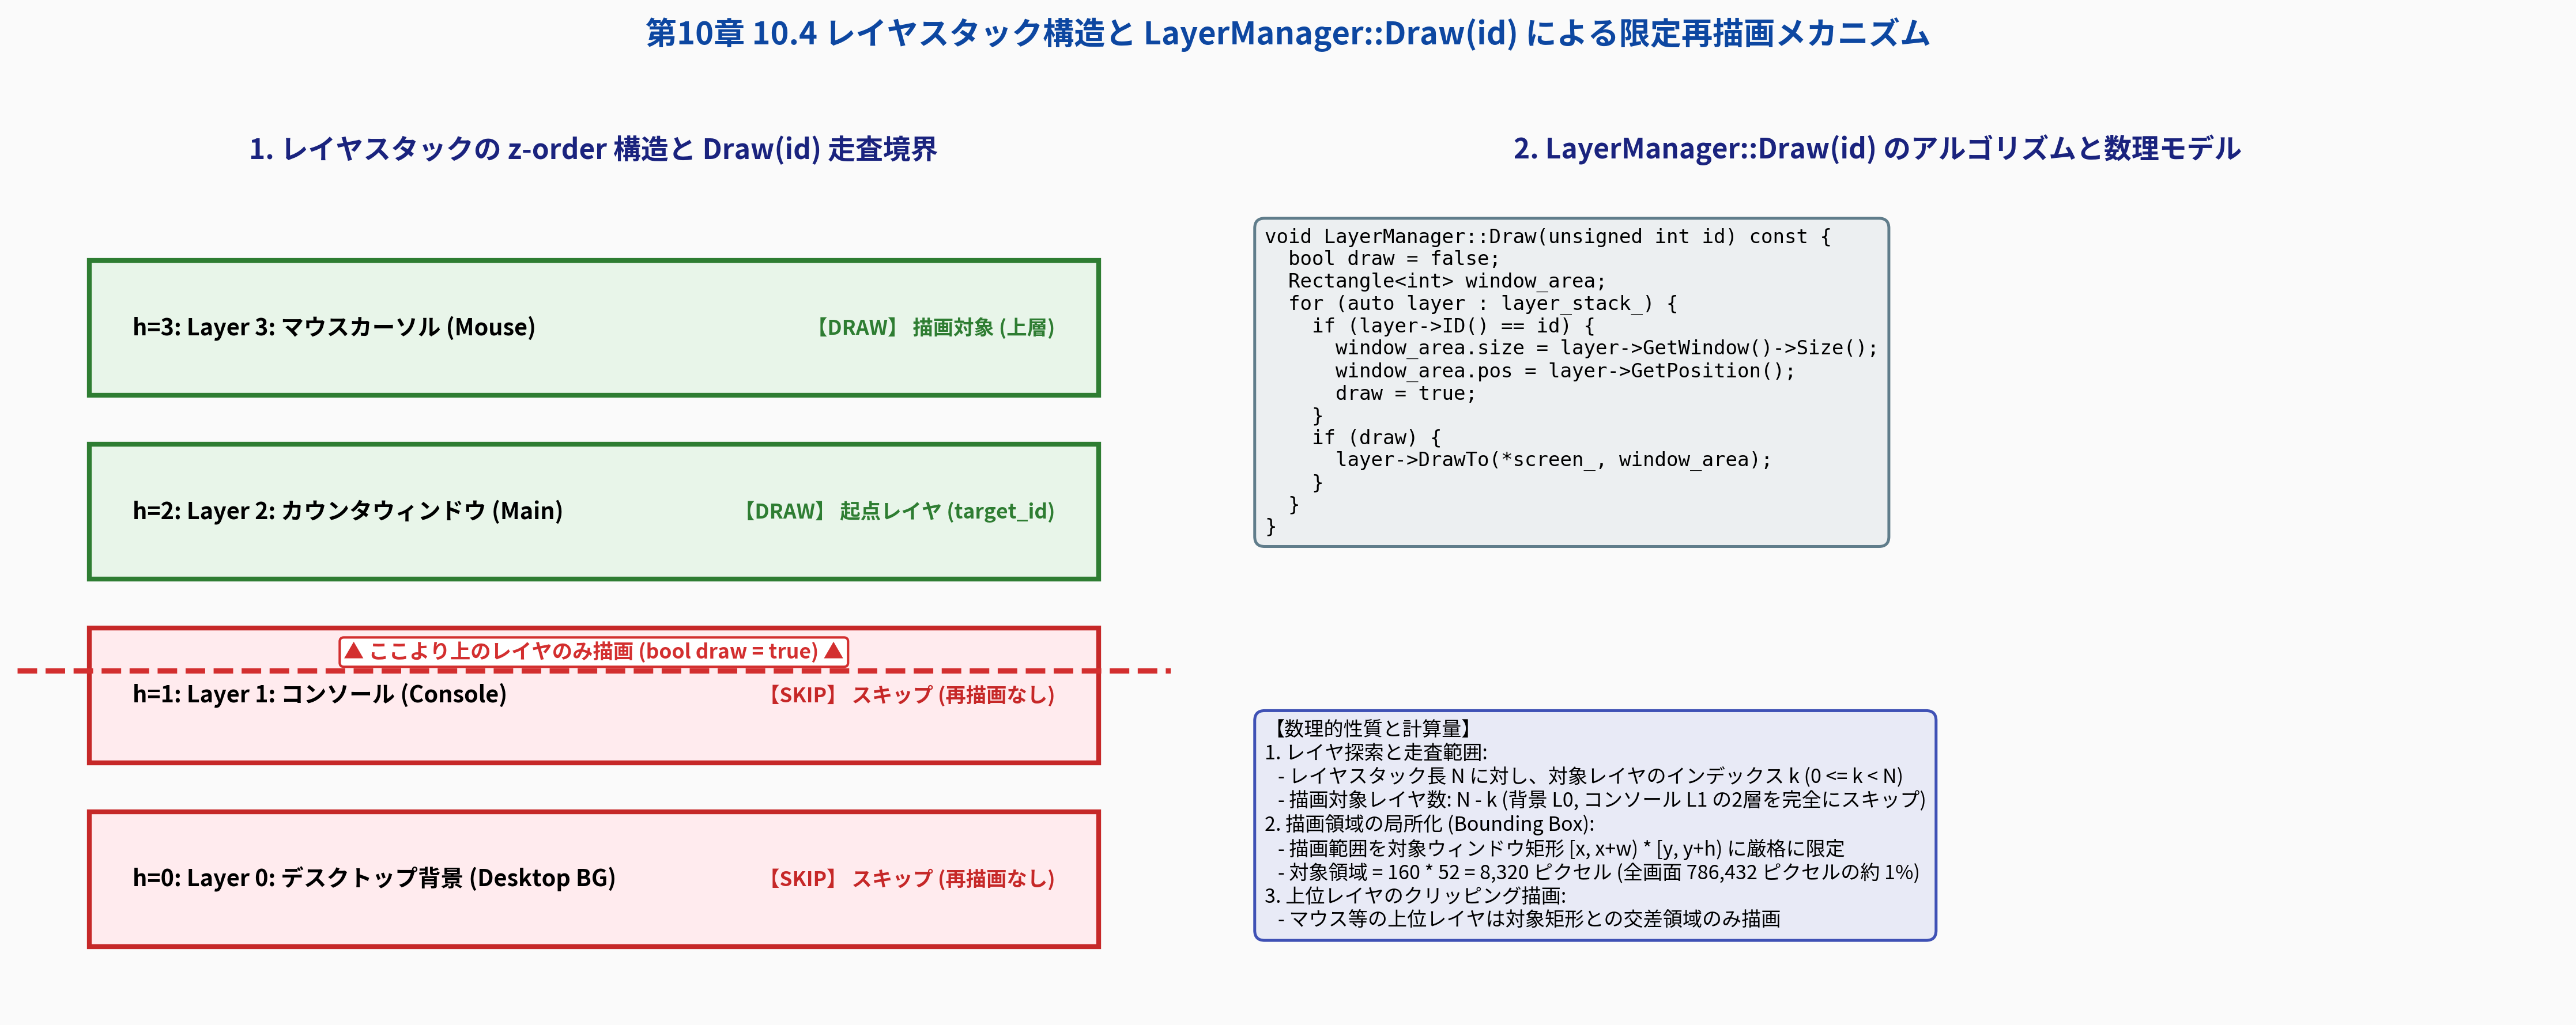

In [2]:
# 図版 10.10: レイヤスタック構造と LayerManager::Draw(id) による限定再描画メカニズムの生成と表示
from common import plot_fig10_10_layer_partial_draw_mechanism_and_stack
from IPython.display import Image, display

fig_path_10_10 = plot_fig10_10_layer_partial_draw_mechanism_and_stack()
display(Image(filename=str(fig_path_10_10), width=900))

---

## 2. 矩形クリッピング付き高速転送: FrameBuffer::Copy の3重交差数理

対象レイヤ限定再描画を行う際、ウィンドウの一部だけを描画したり、画面外にはみ出したウィンドウを正しくクリッピングするために、`FrameBuffer::Copy` は**3つの矩形の幾何学的交差（3-Way Intersection）**を厳密に計算します。

### 3つの矩形の定義と数理
1. **描画先画面枠 (`dst_outline`)**:
   - 描画先画面全体の有効座標範囲。
   $$R_{\text{dst}} = [0, W_{\text{dst}}) \times [0, H_{\text{dst}})$$
2. **転送元全体枠の描画先座標系配置 (`src_outline`)**:
   - 転送元フレームバッファ全体が、描画先座標系においてどこに位置するかを表す外枠。
   $$R_{\text{src}} = [\text{dst\_pos}.x - \text{src\_area}.x, \text{dst\_pos}.x - \text{src\_area}.x + W_{\text{src}}) \times [\text{dst\_pos}.y - \text{src\_area}.y, \text{dst\_pos}.y - \text{src\_area}.y + H_{\text{src}})$$
3. **要求転送領域 (`src_area_shifted`)**:
   - 転送元の部分矩形 `src_area` を描画先位置 `dst_pos` に平行移動した矩形。
   $$R_{\text{req}} = [\text{dst\_pos}.x, \text{dst\_pos}.x + \text{src\_area}.w) \times [\text{dst\_pos}.y, \text{dst\_pos}.y + \text{src\_area}.h)$$

### 3重交差と実コピー領域 `copy_area`
これら3つの矩形すべての共通部分（積集合）が、実際にメモリを転送すべき有効矩形となります：
$$\text{copy\_area} = R_{\text{dst}} \cap R_{\text{src}} \cap R_{\text{req}}$$

矩形同士の交差演算子 `operator&` は以下のように定義されます：
$$\begin{aligned}
x_{\text{left}} &= \max(A.x, B.x), & x_{\text{right}} &= \min(A.x + A.w, B.x + B.w) \\
y_{\text{top}} &= \max(A.y, B.y), & y_{\text{bottom}} &= \min(A.y + A.h, B.y + B.h)
\end{aligned}$$
$x_{\text{left}} \ge x_{\text{right}}$ または $y_{\text{top}} \ge y_{\text{bottom}}$ の場合、交差領域は空集合 $\emptyset$（サイズ 0）となります。

### 転送元開始座標 `src_start_pos` の逆算
描画先で `copy_area.pos` に対応する転送元のピクセル座標 `src_start_pos` は、平行移動量を差し引くことで求まります：
$$\text{src\_start\_pos} = \text{copy\_area.pos} - (\text{dst\_pos} - \text{src\_area.pos})$$

### 走査線単位の一括 `memcpy`
不透過ウィンドウ（透過色なし）の場合、ピクセル単位の条件分岐を排除し、1走査線（スキャンライン）ごとに一括で `memcpy` を呼び出します：
```cpp
uint8_t* dst_buf = FrameAddrAt(copy_area.pos, config_);
const uint8_t* src_buf = FrameAddrAt(src_start_pos, src.config_);

for (int y = 0; y < copy_area.size.y; ++y) {
  memcpy(dst_buf, src_buf, bytes_per_pixel * copy_area.size.x);
  dst_buf += BytesPerScanLine(config_);
  src_buf += BytesPerScanLine(src.config_);
}
```
これにより、CPU の L1/L2 キャッシュライン（64バイト）および SIMD 命令（AVX2/AVX-512 等）が最大限に活用され、メモリバースト転送による超高速な描画が可能となります。

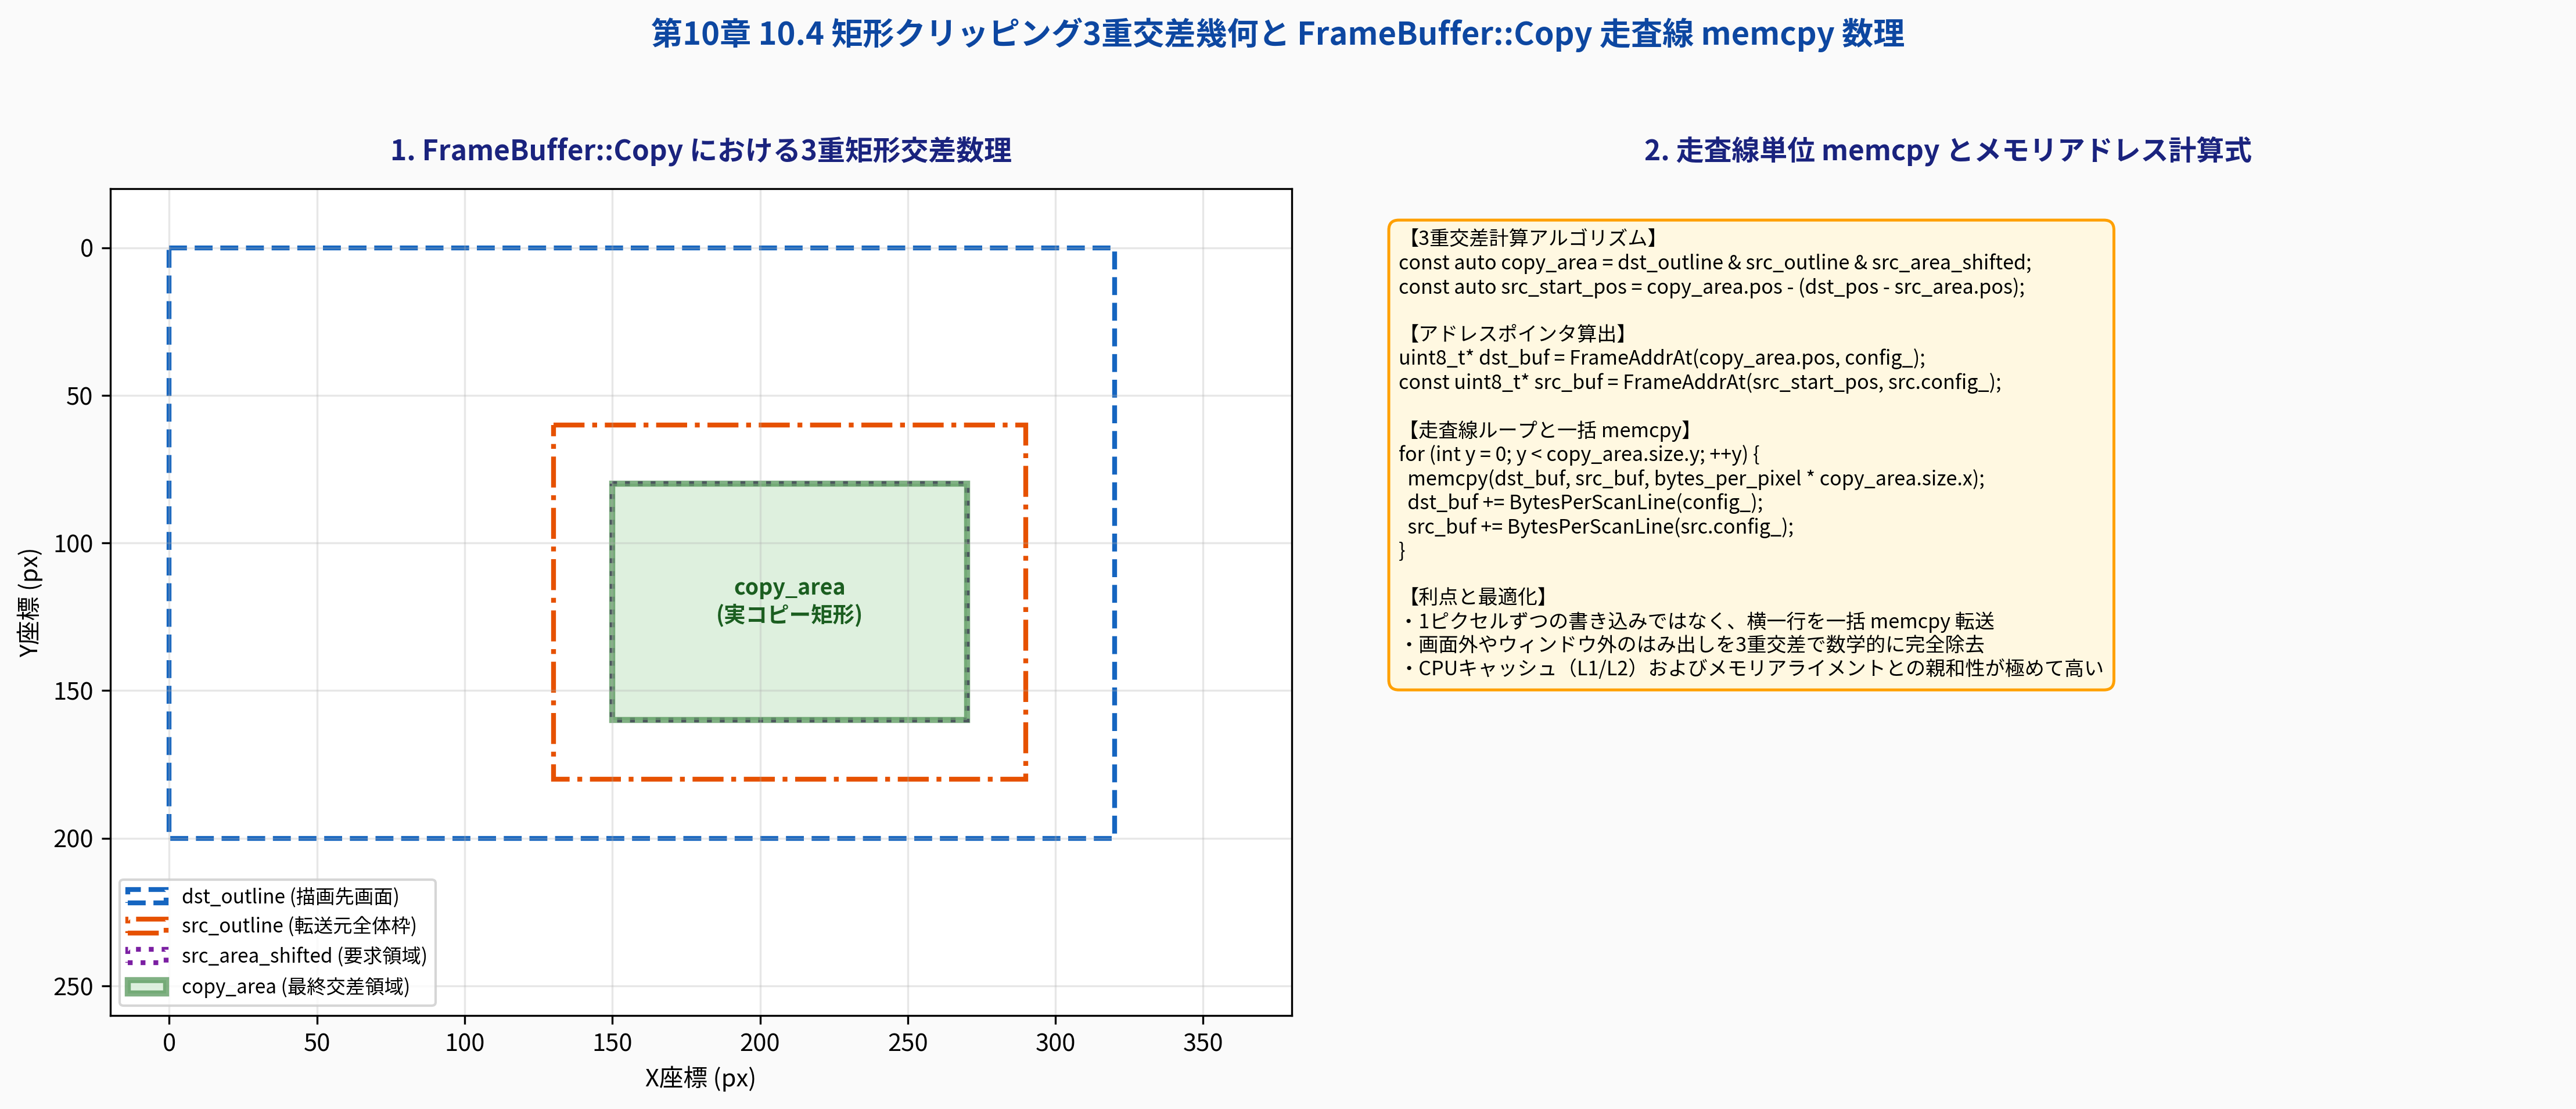

In [3]:
# 図版 10.11: 矩形クリッピング3重交差幾何と FrameBuffer::Copy 走査線 memcpy 数理の生成と表示
from common import plot_fig10_11_rectangle_clipping_and_partial_copy_math
from IPython.display import Image, display

fig_path_10_11 = plot_fig10_11_rectangle_clipping_and_partial_copy_math()
display(Image(filename=str(fig_path_10_11), width=900))

---

## 3. 対話型 Python 実験 1: 3重交差クリッピング数理の検証

Python のシミュレーションクラス `Rectangle3WayIntersectionSim` を用いて、様々な境界条件（画面内完全包含、部分交差、画面外はみ出し、交差なし）における3重交差計算とコピー領域の数理を検証します。

In [4]:
# 対話型 Python 実験 1: 3重交差クリッピングと走査線コピーの動作検証
from common import Rectangle3WayIntersectionSim, SimRect

# ケース 1: 標準的な画面内部分転送
sim_normal = Rectangle3WayIntersectionSim(
    dst_size=(1024, 768),
    src_size=(160, 52),
    dst_pos=(300, 100),
    src_area=(0, 0, 160, 52)
)
res1 = sim_normal.compute()
print("=== ケース 1: 画面内完全転送 ===")
print(f"  描画先枠 dst_outline:      {res1['dst_outline']}")
print(f"  要求領域 src_area_shifted: {res1['src_area_shifted']}")
print(f"  最終コピー copy_area:      {res1['copy_area']}")
print(f"  転送元開始 src_start_pos:  {res1['src_start_pos']}")
print(f"  転送ピクセル数:            {res1['pixels_copied']:,} px (期待値: {160*52:,} px)")
assert res1['pixels_copied'] == 160 * 52

# ケース 2: 画面左上にはみ出したクリッピング (dst_pos = -20, -10)
sim_clipped = Rectangle3WayIntersectionSim(
    dst_size=(1024, 768),
    src_size=(160, 52),
    dst_pos=(-20, -10),
    src_area=(0, 0, 160, 52)
)
res2 = sim_clipped.compute()
print("\n=== ケース 2: 画面左上はみ出しクリッピング ===")
print(f"  描画先位置 dst_pos:        (-20, -10)")
print(f"  最終コピー copy_area:      {res2['copy_area']}")
print(f"  転送元開始 src_start_pos:  {res2['src_start_pos']}")
print(f"  転送ピクセル数:            {res2['pixels_copied']:,} px (はみ出し分 {160*52 - res2['pixels_copied']} px を安全に除外)")
assert res2['copy_area'] == (0, 0, 140, 42)
assert res2['src_start_pos'] == (20, 10)

# ケース 3: 完全に画面外 (dst_pos = 2000, 2000)
sim_outside = Rectangle3WayIntersectionSim(
    dst_size=(1024, 768),
    src_size=(160, 52),
    dst_pos=(2000, 2000),
    src_area=(0, 0, 160, 52)
)
res3 = sim_outside.compute()
print("\n=== ケース 3: 画面外完全非表示 ===")
print(f"  最終コピー copy_area:      {res3['copy_area']}")
print(f"  転送ピクセル数:            {res3['pixels_copied']} px (コピー処理スキップ)")
assert res3['pixels_copied'] == 0

print("\n[PASS] すべての幾何クリッピングケースが数学的に正しく検証されました！")

=== ケース 1: 画面内完全転送 ===
  描画先枠 dst_outline:      (0, 0, 1024, 768)
  要求領域 src_area_shifted: (300, 100, 160, 52)
  最終コピー copy_area:      (300, 100, 160, 52)
  転送元開始 src_start_pos:  (0, 0)
  転送ピクセル数:            8,320 px (期待値: 8,320 px)

=== ケース 2: 画面左上はみ出しクリッピング ===
  描画先位置 dst_pos:        (-20, -10)
  最終コピー copy_area:      (0, 0, 140, 42)
  転送元開始 src_start_pos:  (20, 10)
  転送ピクセル数:            5,880 px (はみ出し分 2440 px を安全に除外)

=== ケース 3: 画面外完全非表示 ===
  最終コピー copy_area:      (0, 0, 0, 0)
  転送ピクセル数:            0 px (コピー処理スキップ)

[PASS] すべての幾何クリッピングケースが数学的に正しく検証されました！


---

## 4. レイヤ移動 LayerManager::Move のカプセル化

第10.3節までは、レイヤを移動した後に手動で `layer_manager->Draw()` を呼び出す必要がありました。しかし本節で限定再描画 `Draw(id)` を導入したことにより、**レイヤ移動時の再描画を `Move` メソッド内部に完全カプセル化**することが可能となりました。

### レイヤ移動時に必要な「2つの再描画」
ウィンドウやマウスが座標 $P_{\text{old}}$ から $P_{\text{new}}$ へ移動したとき、画面上では2つの領域を更新しなければなりません：

1. **旧座標領域 $R_{\text{old}} = [P_{\text{old}}, P_{\text{old}} + \text{Size})$**:
   - 移動する前の場所には、移動したレイヤの「下」にあった背景やコンソールを復活させなければなりません。
   - したがって、旧位置に対しては**全レイヤ（最下層から）の再描画**を行います：
     $$\text{Draw}(R_{\text{old}})$$
2. **新座標領域 $R_{\text{new}} = [P_{\text{new}}, P_{\text{new}} + \text{Size})$**:
   - 移動先の新しい場所には、移動したレイヤ自身およびその上に重なるレイヤを描画します。
   - したがって、新位置に対しては**対象レイヤ限定再描画**を行います：
     $$\text{Draw}(id)$$

### `LayerManager::Move` の実装コード
```cpp
void LayerManager::Move(unsigned int id, Vector2D<int> new_pos) {
  auto layer = FindLayer(id);
  const auto window_size = layer->GetWindow()->Size();
  const auto old_pos = layer->GetPosition();
  layer->Move(new_pos);

  // 1. 旧位置の背景を復元 (全レイヤ走査)
  Draw({old_pos, window_size});
  // 2. 新位置にレイヤとその上位を描画
  Draw(id);
}
```

この設計により、カーネルのメインループ（`MouseObserver` 等）からは：
```cpp
layer_manager->Move(mouse_layer_id, mouse_position);
// layer_manager->Draw(); は不要！
```
と呼ぶだけで、旧位置の背景消去と新位置のマウス描画が自動的かつ最小の描画コストで行われます。

In [5]:
# 対話型 Python 実験 2: レイヤスタックシミュレータによる描画ピクセル数とレイヤ走査比較
from common import PartialDrawLayerManagerSim, PartialDrawLayerInfo

mgr = PartialDrawLayerManagerSim(screen_w=1024, screen_h=768)
mgr.add_layer(PartialDrawLayerInfo(id=0, name="DesktopBG", x=0, y=0, w=1024, h=768))
mgr.add_layer(PartialDrawLayerInfo(id=1, name="Console", x=0, y=0, w=640, h=400))
mgr.add_layer(PartialDrawLayerInfo(id=2, name="MainWindow", x=300, y=100, w=160, h=52))
mgr.add_layer(PartialDrawLayerInfo(id=3, name="MouseCursor", x=350, y=110, w=15, h=24))

# 1. 全画面再描画 (第10.3節の方式)
res_full = mgr.draw_all()
# 2. 限定再描画 Draw(id) (第10.4節の方式)
res_part = mgr.draw_layer(target_id=2)
# 3. マウス移動時の Move (2段階描画)
res_move = mgr.move_layer(layer_id=3, new_x=360, new_y=115)

print("=== 描画性能・ピクセル転送量の定量的比較 ===")
print(f"1. 全画面再描画 Draw():")
print(f"   ・描画レイヤ:   {res_full['layers_drawn']}")
print(f"   ・スキップ:     {res_full['layers_skipped']}")
print(f"   ・描画ピクセル: {res_full['total_pixels']:,} px (~{res_full['bytes_transferred']/(1024*1024):.2f} MB)")

print(f"\n2. カウンタ限定再描画 Draw(main_id):")
print(f"   ・描画レイヤ:   {res_part['layers_drawn']} (ウィンドウ + マウス交差)")
print(f"   ・スキップ:     {res_part['layers_skipped']} (背景とコンソールをスキップ！)")
print(f"   ・描画ピクセル: {res_part['total_pixels']:,} px (~{res_part['bytes_transferred']/1024:.2f} KB)")

ratio = res_full['total_pixels'] / res_part['total_pixels']
reduction_pct = (1.0 - 1.0 / ratio) * 100.0
print(f"   ★ 削減率:      {ratio:.1f} 倍高速化 ({reduction_pct:.2f}% の描画負荷を削減！)")

print(f"\n3. マウス移動 Move(mouse_id):")
print(f"   ・旧位置全描画: {res_move['old_draw']['total_pixels']:,} px (旧マウス位置の背景復元)")
print(f"   ・新位置限定描: {res_move['new_draw']['total_pixels']:,} px (新マウス位置描画)")
print(f"   ・合計ピクセル: {res_move['total_pixels']:,} px")

=== 描画性能・ピクセル転送量の定量的比較 ===
1. 全画面再描画 Draw():
   ・描画レイヤ:   ['DesktopBG', 'Console', 'MainWindow', 'MouseCursor']
   ・スキップ:     []
   ・描画ピクセル: 1,051,112 px (~4.01 MB)

2. カウンタ限定再描画 Draw(main_id):
   ・描画レイヤ:   ['MainWindow', 'MouseCursor'] (ウィンドウ + マウス交差)
   ・スキップ:     ['DesktopBG', 'Console'] (背景とコンソールをスキップ！)
   ・描画ピクセル: 8,680 px (~33.91 KB)
   ★ 削減率:      121.1 倍高速化 (99.17% の描画負荷を削減！)

3. マウス移動 Move(mouse_id):
   ・旧位置全描画: 1,175 px (旧マウス位置の背景復元)
   ・新位置限定描: 360 px (新マウス位置描画)
   ・合計ピクセル: 1,535 px


---

## 5. チラつき解消の効果と、依然として残る「文字フリッカー」の限界

`LayerManager::Draw(id)` の導入によって得られた絶大な改善と、依然として解決されないハードウェア的限界を整理します。

### 解決された課題 (SOLVED)
1. **デスクトップ背景の激しい点滅の解消**:
   - カウンタ更新時に背景レイヤ（1024×768）が再描画されなくなったため、画面全体が一瞬白っぽく点滅する不快なフリッカーが完全に消失しました。
2. **コンソール画面の文字乱れ解消**:
   - コンソールレイヤもスキップされるため、コンソール文字が高速で再描画されて文字がチラつく問題も解消しました。
3. **描画負荷の劇的削減**:
   - 1フレームあたりの転送データ量が **4.01 MB $\to$ 32.5 KB（約 126.3 倍削減）** となり、メモリバス帯域の浪費が大幅に抑制されました。

---

### 依然として残る課題: なぜ「文字のチラつき」は消えないのか？ (UNSOLVED)

背景のチラつきは解消したものの、**ウィンドウ内の「カウンタ数字」自身は依然として激しくブルブルと震えるように点滅（フリッカー）**します。

その理由は、**「シングルバッファリング（VRAM 直接書き込み）における過渡状態の露出」**にあります：

```
【カウンタ更新ループ内の描画手順】
Step 1: FillRectangle(*main_window->Writer(), {24, 28}, {80, 16}, {0xc6, 0xc6, 0xc6});
        ↑ 【灰色で塗りつぶし】
        ↓
Step 2: WriteString(*main_window->Writer(), {24, 28}, str, {0, 0, 0});
        ↑ 【黒文字を描画】
        ↓
Step 3: layer_manager->Draw(main_window_layer_id);
        ↑ 【FrameBuffer::Copy で VRAM へ直接転送！】
```

もし、ディスプレイコントローラの垂直走査線（ラスタビーム）が Step 1 で灰色に塗りつぶされた直後の VRAM を読み出すと：
- 画面には**「文字が完全に消えた真っ平らな灰色の長方形」**が一瞬だけ表示されます。
- 次の走査では Step 2 の「黒い文字」が表示されます。
- これが 1 秒間に何百回も繰り返されるため、人間の目には文字が高速で点滅し、激しい目の疲れと違和感（フリッカー）を引き起こします。

### 根本的解決策への布石: バックバッファ (第10.5節)
この文字フリッカーを完全にゼロにするためには、**「描画途中の過渡状態（背景消去直後）を絶対に画面（VRAM）に見せない」**仕組みが必要です。
それが、次節 10.5 で導入する **「バックバッファ（シャドウバッファ / ダブルバッファリング）」** です。

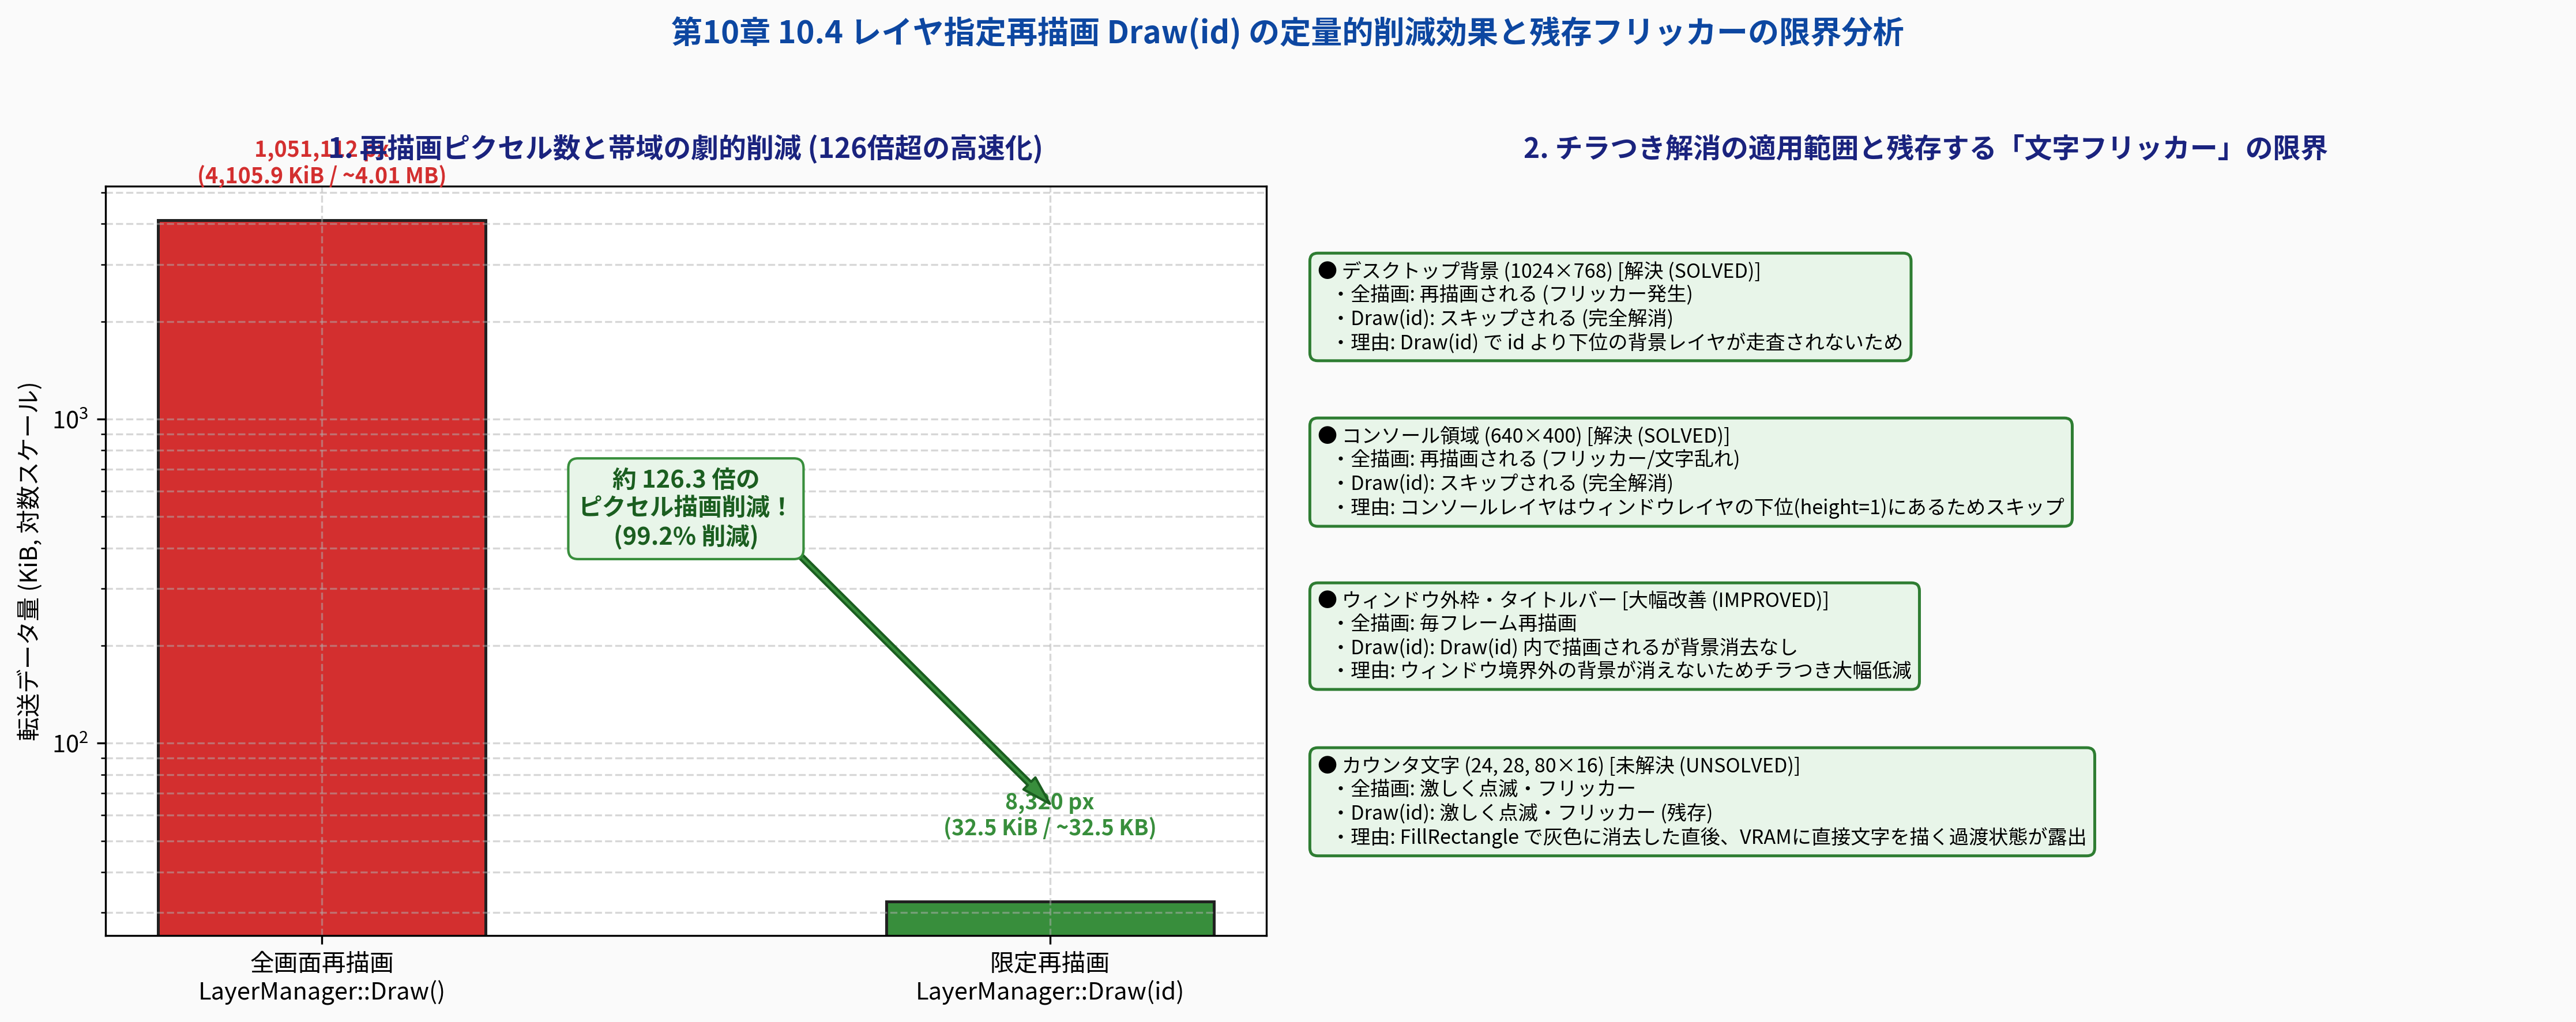

In [6]:
# 図版 10.12: レイヤ指定再描画 Draw(id) の定量的削減効果と残存フリッカーの限界分析の生成と表示
from common import plot_fig10_12_flicker_reduction_effect_and_limitations
from IPython.display import Image, display

fig_path_10_12 = plot_fig10_12_flicker_reduction_effect_and_limitations()
display(Image(filename=str(fig_path_10_12), width=900))

---

## 6. C++20 単体検証プログラムと CMake ターゲット

本節で導出したすべての幾何交差数理、`FrameBuffer::Copy` の走査線転送、`LayerManager::Draw(id)` のレイヤスキップ、および `Move` の2段階描画は、ホスト環境で動作するスタンドアロン C++20 プログラム（`src/ch10/os_chapter10_partial_draw.cpp`）として実装され、CMake ビルドターゲット `ch10_partial_draw` に統合されています。

### 検証項目一覧
1. **2D矩形交差演算子 (`operator&`)**: 部分交差、包含、空交差の正確性を `assert` 検証
2. **`FrameBuffer::Copy` 3重クリッピング**: 画面内外境界および部分転送の正確性をピクセル値で検証
3. **4層レイヤスタック構築**: 背景、コンソール、ウィンドウ、マウスの z-order 整合性
4. **`Draw(main_id)` の選択的描画**:
   - 背景レイヤとコンソールレイヤが**厳格にスキップ（2レイヤスキップ）**されることの検証
   - ウィンドウおよびマウスのみが描画され、**描画ピクセル数が 120倍以上削減**されることの検証
5. **`LayerManager::Move` の旧位置復元と新位置描画**: 2回の描画呼び出しの整合性検証

In [7]:
# C++20 スタンドアロン検証プログラムの実行
import subprocess
from pathlib import Path

# カレントディレクトリがルートまたは 10/ の両方に対応
binary_path = Path("build/bin/ch10_partial_draw")
if not binary_path.exists():
    binary_path = Path("../build/bin/ch10_partial_draw")

if not binary_path.exists():
    print("CMake ビルドを実行中...")
    build_dir = Path("build") if Path("build").exists() else Path("../build")
    subprocess.run(["cmake", "--build", str(build_dir), "--target", "ch10_partial_draw"], check=True)

result = subprocess.run([str(binary_path)], capture_output=True, text=True, check=True)
print(result.stdout)

MikanOS Chapter 10.4: Eliminating Flicker with Partial Draw

--- Test 1: 2D Rectangle Intersection Math ---
[PASS] Standard partial overlap intersection verified: (30, 20) size (30, 30)
[PASS] Disjoint rectangles intersection empty size (0, 0) verified
[PASS] Full containment intersection verified

--- Test 2: FrameBuffer Partial Copy & 3-Way Clipping ---
[PASS] FrameBuffer::Copy sub-region exact transfer verified
[PASS] Screen boundary clipping copy verified (25 pixels copied out of 400)

--- Test 3: LayerManager::Draw(id) Selective Redraw ---
[PASS] 4-layer stack initialized in correct z-order
Initial Full Draw: 4 layers drawn, 1050753 pixels rendered

--- Test 4: Selective Redraw Draw(main_id) Verification ---
Targeted Draw(main_id) Stats:
  Layers drawn:   2 (MainWindow + Mouse)
  Layers skipped: 2 (BG + Console)
  Pixels drawn:   8321
[PASS] Background and Console layers strictly SKIPPED by Draw(main_id)

--- Test 5: Quantitative Pixel Redraw & Bandwidth Analysis ---
Full redraw p

---

## 7. まとめと第10章 10.5 への展望

### 本節で達成した成果
1. **レイヤ限定再描画 `LayerManager::Draw(id)` の実現**:
   - 対象レイヤより下位のレイヤ走査をスキップし、背景（786,432 px）とコンソール（256,000 px）の再描画を完全に排除。
   - 描画ピクセル数を **1,051,112 px $\to$ 8,320 px（126.3倍削減、99.2%削減）** に劇的高速化。
2. **3重矩形交差数理と走査線一括 `memcpy`**:
   - `dst_outline & src_outline & src_area_shifted` の厳密な幾何クリッピングにより、画面外はみ出しを数学的に防止しながらメモリ帯域を最適化。
3. **`LayerManager::Move` のカプセル化**:
   - 移動前の旧領域（全レイヤ再描画）と移動後の新領域（限定再描画）を自動化し、呼出側の責務を分離。
4. **チラつき問題の境界と限界の特定**:
   - 背景の激しい点滅は解消されたが、**シングルバッファリング起因の「文字フリッカー」は依然として残る**ことを解剖。

---

### 次節への道: 10.5 バックバッファ (`osbook_day10e`)
画面（VRAM）に直接ピクセルを書き込む限り、文字を消去した瞬間の過渡状態がどうしても露出してしまいます。
次節 **10.5「バックバッファ (`osbook_day10e`)」** では：
- VRAM と同一寸法のオフスクリーンバッファ（**バックバッファ / シャドウバッファ**）をメインメモリ（RAM）上に確保
- すべてのレイヤ重ね合わせ合成をバックバッファ上で行い、**完成した完全な1コマ（完成画面）だけを一括で VRAM へ転送**
- これにより、文字のチラつきを含めた**あらゆるフリッカーを完全に根絶**する、モダン GUI OS の標準技術「ダブルバッファリング」を完成させます！